# 05 · Pronóstico de demanda y alerta de saturación
- Llegadas **diarias** a urgencias, pronóstico **a 1 día**: ingenuo vs Holt-Winters vs LightGBM (calendario + rezagos).
- **Alerta**: día con pico de ocupación > P90 histórico.
- Validación con los últimos 120 días (abril 2026 incluido).

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src import datos, flow
from src.config import FIGURES, DATA_INTERIM, DATA_PROCESSED, ETAPAS
pd.set_option("display.max_columns", 50); pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", context="notebook")
def guardar(nombre):
    plt.tight_layout(); plt.savefig(FIGURES / f"{nombre}.png", dpi=150, bbox_inches="tight"); plt.show()
import lightgbm as lgb, holidays
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, roc_auc_score

In [2]:
ep = datos.episodios()
occ = pd.read_parquet(DATA_INTERIM / "ocupacion_horaria.parquet")
d = ep[ep.primera_etapa != 9201].set_index("inicio").resample("D").size().rename("llegadas").to_frame()
d["pico_ocup"] = occ.set_index("fecha_hora").ocupacion.resample("D").max()
d = d.loc["2023-01-08":"2026-04-30"].dropna()
umbral = d.pico_ocup.quantile(.9); d["saturado"] = (d.pico_ocup > umbral).astype(int)
print(f"Umbral de saturación (P90 del pico diario): {umbral:.0f} pacientes · días saturados: {d.saturado.sum()}")
H = 120; train, test = d.iloc[:-H], d.iloc[-H:]

Umbral de saturación (P90 del pico diario): 316 pacientes · días saturados: 121


In [3]:
# Holt-Winters re-ajustado cada día (pronóstico a 1 día, como se usaría en operación)
hw_pred = []
for i in range(H):
    hist = d.llegadas.iloc[:len(d) - H + i]
    hw_pred.append(ExponentialSmoothing(hist.iloc[-365:], trend="add", damped_trend=True, seasonal="add", seasonal_periods=7).fit().forecast(1).iloc[0])
pred_hw = pd.Series(hw_pred, index=test.index)
co = holidays.Colombia(years=range(2023, 2027))
def feats(df):
    X = pd.DataFrame(index=df.index)
    X["dow"] = df.index.dayofweek; X["mes"] = df.index.month; X["dia_mes"] = df.index.day
    X["festivo"] = [x in co for x in df.index.date]; X["festivo"] = X.festivo.astype(int)
    X["post_festivo"] = X.festivo.shift(1, fill_value=0)
    X["tendencia"] = np.arange(len(df))
    for l in [1, 2, 3, 7, 14, 21, 28]: X[f"lag{l}"] = df.llegadas.shift(l)
    X["media7"] = df.llegadas.shift(1).rolling(7).mean(); X["media28"] = df.llegadas.shift(1).rolling(28).mean()
    return X
X = feats(d)
gbm = lgb.LGBMRegressor(n_estimators=600, learning_rate=0.03, num_leaves=15, verbose=-1, random_state=42)
gbm.fit(X.iloc[28:-H], d.llegadas.iloc[28:-H]); pred_gbm = gbm.predict(X.iloc[-H:])
pred_mix = (pred_gbm + pred_hw.values) / 2
naive = d.llegadas.shift(7).iloc[-H:]
met = pd.DataFrame({m: {"MAE": mean_absolute_error(test.llegadas, p), "MAPE_%": mean_absolute_percentage_error(test.llegadas, p) * 100}
                    for m, p in {"Ingenuo (misma día semana pasada)": naive, "Holt-Winters": pred_hw, "LightGBM": pred_gbm, "Promedio HW + LightGBM": pred_mix}.items()}).T
met

,MAE,MAPE_%
Ingenuo (misma día semana pasada),72.09,17.89
Holt-Winters,52.02,13.59
LightGBM,59.47,16.87
Promedio HW + LightGBM,52.59,14.52


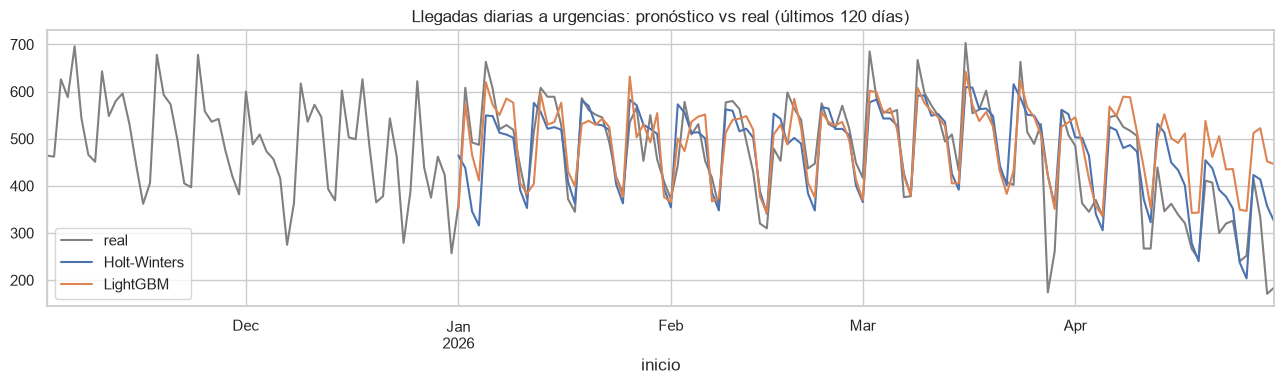

In [4]:
fig, ax = plt.subplots(figsize=(13, 4))
d.llegadas.iloc[-H-60:].plot(ax=ax, color="gray", label="real")
pd.Series(pred_hw.values, test.index).plot(ax=ax, label="Holt-Winters"); pd.Series(pred_gbm, test.index).plot(ax=ax, label="LightGBM")
ax.legend(); ax.set_title("Llegadas diarias a urgencias: pronóstico vs real (últimos 120 días)")
guardar("05_pronostico_llegadas")

### Alerta de saturación (clasificador del día siguiente con información disponible hoy)

In [5]:
Xa = X.copy(); Xa["pico_ayer"] = d.pico_ocup.shift(1); Xa["pico_media7"] = d.pico_ocup.shift(1).rolling(7).mean()
Xa["llegadas_pred"] = gbm.predict(X.fillna(X.median()))
clf = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.03, num_leaves=15, class_weight="balanced", verbose=-1, random_state=42)
clf.fit(Xa.iloc[28:-H], d.saturado.iloc[28:-H]); p = clf.predict_proba(Xa.iloc[-H:])[:, 1]
print("AUC alerta:", round(roc_auc_score(test.saturado, p), 3) if test.saturado.nunique() > 1 else "sin días saturados en test")
alerta = test.assign(prob_saturacion=p, alerta=(p >= .5).astype(int))
pd.crosstab(alerta.saturado, alerta.alerta, rownames=["real"], colnames=["alerta"])

AUC alerta: 0.922


alerta,0,1
real,,
0,111,4
1,3,2


In [6]:
pron = pd.DataFrame({"fecha": test.index, "llegadas_real": test.llegadas.values, "pred_holt_winters": pred_hw.values,
                     "pred_lightgbm": pred_gbm, "pico_ocupacion": test.pico_ocup.values, "prob_saturacion": p})
pron.to_parquet(DATA_INTERIM / "pronostico.parquet", index=False); met.to_parquet(DATA_INTERIM / "metricas_pronostico.parquet")